<a href="https://colab.research.google.com/github/Bless-O/human-mtbi-aperiodic-eeg/blob/main/02_bad_channel_and_pilot_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q mne mne-bids mne-icalabel specparam openneuro-py

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne_bids import BIDSPath, read_raw_bids
from mne_icalabel import label_components
from specparam import SpectralGroupModel
if not os.path.exists('/content/mtbi_data/sub-001'):
    !openneuro-py download \
        --dataset=ds005114 \
        --target-dir=/content/mtbi_data \
        --include=participants.tsv \
        --include=dataset_description.json \
        --include=sub-001/* \
        --include=sub-002/*

2: Reusable Preprocessing + specparam Pipeline.
Delineates the order of operations: Filter → Flag & Interpolate Bad Channels → Average Reference → ICA/ICLabel → All-Channel specparam.

In [2]:
def process_subject(subject_id, session='01', task='DPX', root='/content/mtbi_data'):
    # 1. Load BIDS data
    bids_path = BIDSPath(root=root, subject=subject_id, session=session, task=task, datatype='eeg')
    raw = read_raw_bids(bids_path, verbose=False)
    raw.load_data()

    # 2. Fix BIDS "n/a" channel types & attach montage
    ch_types = {
        ch: ('eog' if 'EOG' in ch.upper() else 'ecg' if ('EKG' in ch.upper() or 'ECG' in ch.upper()) else 'eeg')
        for ch in raw.ch_names
    }
    raw.set_channel_types(ch_types)
    raw.set_montage('colin27_1020', on_missing='ignore')
    raw_eeg = raw.copy().pick('eeg')

    # 3. Bandpass filter (1-100 Hz for ICLabel)
    raw_filt = raw_eeg.copy().filter(l_freq=1.0, h_freq=100.0, verbose=False)

    # 4. Blink-proof bad-channel detection (15-100 Hz copy) BEFORE avg ref
    raw_hf = raw_filt.copy().filter(l_freq=15.0, h_freq=None, verbose=False)
    ch_stds_hf = np.std(raw_hf.get_data(), axis=1)
    med = np.median(ch_stds_hf)
    mad = np.median(np.abs(ch_stds_hf - med)) * 1.4826
    robust_z = (ch_stds_hf - med) / (mad + 1e-12)

    ch_stds_full = np.std(raw_filt.get_data(), axis=1)
    bad_idx = np.where((robust_z > 5.0) | (ch_stds_full < 1e-7))[0]
    bad_chs = [raw_filt.ch_names[i] for i in bad_idx]
    print(f"sub-{subject_id} | Flagged bad channels ({len(bad_chs)}): {bad_chs}")

    if bad_chs:
        raw_filt.info['bads'] = bad_chs
        raw_filt.interpolate_bads(reset_bads=True, verbose=False)

    # 5. Average reference (now safe from bad-channel smearing)
    raw_filt.set_eeg_reference('average', projection=False, verbose=False)

    # 6. Extended Infomax ICA (30 components) + ICLabel
    ica = mne.preprocessing.ICA(
        n_components=30,
        method='infomax',
        fit_params=dict(extended=True),
        random_state=42
    )
    ica.fit(raw_filt, verbose=False)

    ic_labels = label_components(raw_filt, ica, method='iclabel')
    exclude_idx = [
        i for i, (lbl, p) in enumerate(zip(ic_labels['labels'], ic_labels['y_pred_proba']))
        if lbl in ['eye blink', 'muscle artifact', 'channel noise'] and p > 0.65
    ]
    print(f"sub-{subject_id} | Excluded ICA components ({len(exclude_idx)}): {exclude_idx}")

    raw_clean = ica.apply(raw_filt.copy(), exclude=exclude_idx, verbose=False)

    # 7. Compute Welch PSD across all 63 EEG channels & fit specparam group model
    psd = raw_clean.compute_psd(method='welch', fmin=2, fmax=40, n_fft=1024, verbose=False)
    freqs = psd.freqs
    spectra = psd.get_data()

    fg = SpectralGroupModel(aperiodic_mode='fixed', peak_width_limits=[1, 12], max_n_peaks=6, verbose=False)
    fg.fit(freqs, spectra, [2, 40])

    exponents = fg.get_params('aperiodic', 'exponent')
    r2s = fg.get_metrics('gof', 'rsquared')
    print(f"sub-{subject_id} | Mean Exponent: {np.nanmean(exponents):.3f} | Median R²: {np.nanmedian(r2s):.3f}\n")

    return raw_clean.info, exponents, r2s

No 3: Run Pilot Comparison & Plot Scalp Topographies.

/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "Fp1" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "Fz" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "F3" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "F7" will be set to "misc".
  raw = read_raw_bids(bid

Reading 0 ... 1098274  =      0.000 ...  2196.548 secs...


/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: There are channels without locations (n/a) that are not marked as bad: ['EKG']
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: Not setting positions of 65 misc channels found in montage:
['Fp1', 'Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'TP9', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'Cz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'FCz', 'C1', 'C5', 'TP7', 'CP3', 'P1', 'P5', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'P6', 'P2', 'CP4', 'TP8', 'C6', 'C2', 'FC4', 'FT8', 'F6', 'F2', 'AF4', 'AF8', 'VEOG', 'EKG']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarni

sub-001 | Flagged bad channels (1): ['T7']
Use rng= instead of random_state= in new code
sub-001 | Excluded ICA components (8): [0, 2, 10, 18, 19, 21, 22, 26]
sub-001 | Mean Exponent: 0.982 | Median R²: 0.991

Reading 0 ... 1102374  =      0.000 ...  2204.748 secs...


/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "Fp1" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "Fz" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "F3" will be set to "misc".
  raw = read_raw_bids(bids_path, verbose=False)
/tmp/ipykernel_4872/2298943357.py:4: RuntimeWarning: No BIDS -> MNE mapping found for channel type "n/a". Type of channel "F7" will be set to "misc".
  raw = read_raw_bids(bid

sub-002 | Flagged bad channels (0): []
Use rng= instead of random_state= in new code
sub-002 | Excluded ICA components (4): [0, 1, 2, 11]
sub-002 | Mean Exponent: 1.082 | Median R²: 0.990



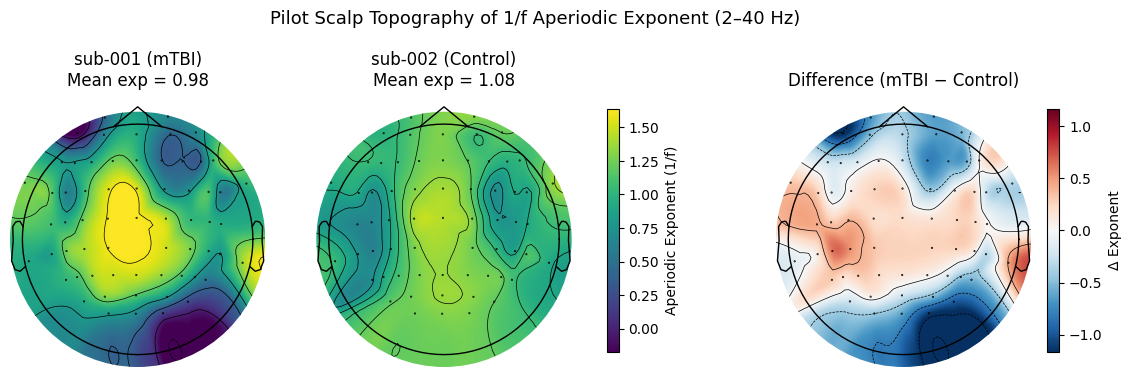

In [3]:
# Run pipeline on sub-001 (mTBI) and sub-002 (Control)
info_mtbi, exp_mtbi, r2_mtbi = process_subject('001')
info_ctrl, exp_ctrl, r2_ctrl = process_subject('002')

# Shared color scale for direct visual comparison
vmin = np.nanmin([exp_mtbi, exp_ctrl])
vmax = np.nanmax([exp_mtbi, exp_ctrl])
diff = exp_mtbi - exp_ctrl
dmax = np.nanmax(np.abs(diff))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

im0, _ = mne.viz.plot_topomap(exp_mtbi, info_mtbi, axes=axes[0], show=False, vlim=(vmin, vmax), cmap='viridis')
axes[0].set_title(f"sub-001 (mTBI)\nMean exp = {np.nanmean(exp_mtbi):.2f}")

im1, _ = mne.viz.plot_topomap(exp_ctrl, info_ctrl, axes=axes[1], show=False, vlim=(vmin, vmax), cmap='viridis')
axes[1].set_title(f"sub-002 (Control)\nMean exp = {np.nanmean(exp_ctrl):.2f}")

im2, _ = mne.viz.plot_topomap(diff, info_mtbi, axes=axes[2], show=False, vlim=(-dmax, dmax), cmap='RdBu_r')
axes[2].set_title("Difference (mTBI − Control)")

# Colorbars
fig.colorbar(im1, ax=axes[:2], shrink=0.75, label="Aperiodic Exponent (1/f)")
fig.colorbar(im2, ax=axes[2], shrink=0.75, label="Δ Exponent")

plt.suptitle("Pilot Scalp Topography of 1/f Aperiodic Exponent (2–40 Hz)", fontsize=13, y=1.02)
plt.show()